# v1 · RSNA Pneumonia, классификатор снимков (ConvNeXt V2 Tiny)

Первая часть проекта. Модель, которая относит рентген грудной клетки к одному из трёх классов.

| Класс | Что значит | Доля |
|---|---|---|
| 0, Normal | норма | 33% |
| 1, No Lung Opacity / Not Normal | есть изменения, но не пневмония | 44% |
| 2, Lung Opacity | пневмония, на снимке есть боксы | 23% |

**Что внутри ноутбука**
1. Загрузка данных и проверка таблиц
2. EDA, классы, боксы, метаданные DICOM, связь проекции AP/PA с классом
3. Препроцессинг DICOM -> массив `512×512 uint8` в памяти
4. Сплит train / val / test (60 / 20 / 20, стратификация по классу и проекции)
5. `Dataset`, `DataLoader`, аугментации
6. Обучение ConvNeXt V2 Tiny с ранней остановкой
7. Проверка на test, проверка shortcut по проекции, Grad-CAM, порог по коэффициенту Жаккара
8. Сохранение `meta_classifier_ConvNeXt_V2_Tiny_no_aug.csv` и `boxes_512_classifier_ConvNeXt_V2_Tiny_no_aug.csv` для ноутбука YOLO

**Итог на test.** ROC-AUC (ovr) 0.890 · macro F1 0.726 · recall класса 2 0.668

> Пути в ноутбуке рассчитаны на Google Colab. Архив соревнования лежит в
> `/content/drive/MyDrive/rsna-pneumonia-detection-challenge.zip`, результаты пишутся в
> `/content/drive/MyDrive/rsna_project_final/`.

## 0. Установка и подключение Google Drive

In [ ]:
!pip install -q pydicom pylibjpeg pylibjpeg-libjpeg timm albumentations grad-cam

In [ ]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


## 1. Данные

Распаковка архива на локальный диск Colab (чтение напрямую с Drive слишком медленное). Маркер `.done` появляется только после успешной распаковки.

In [ ]:
import zipfile
from pathlib import Path

SEED = 42
drive_dir = Path("/content/drive/MyDrive/rsna_project_final")
drive_dir.mkdir(parents=True, exist_ok=True)

zip_path = Path("/content/drive/MyDrive/rsna-pneumonia-detection-challenge.zip")
extract_dir = Path("/content/extract_dir")
done_marker = extract_dir / ".done"

if done_marker.exists():
    print(f"Архив уже распакован в {extract_dir}")
else:
    print("Распаковываю архив...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)
    done_marker.touch()
    print("Архив успешно распакован!")

train_dir = extract_dir / "stage_2_train_images"
print("DICOM в train:", len(list(train_dir.glob("*.dcm"))))

Распаковываю архив...
Архив успешно распакован!
DICOM в train: 26684


In [ ]:
!ls /content/extract_dir

'GCP Credits Request Link - RSNA.txt'   stage_2_test_images
 stage_2_detailed_class_info.csv        stage_2_train_images
 stage_2_sample_submission.csv	        stage_2_train_labels.csv


Файлы соревнования.
- `stage_2_train_labels.csv` - боксы по строчно
- `stage_2_detailed_class_info.csv` - класс снимка (строки повторяются по числу боксов)
- `stage_2_train_images/` - 26 684 DICOM с разметкой
- `stage_2_test_images/` содержит 3 000 снимков без разметки (закрытый тест Kaggle)

In [ ]:
import pandas as pd
detector_info = pd.read_csv('/content/extract_dir/stage_2_train_labels.csv')
class_info = pd.read_csv('/content/extract_dir/stage_2_detailed_class_info.csv')

class_info.head()

,patientId,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,No Lung Opacity / Not Normal
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,No Lung Opacity / Not Normal
2,00322d4d-1c29-4943-afc9-b6754be640eb,No Lung Opacity / Not Normal
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,Normal
4,00436515-870c-4b36-a041-de91049b9ab4,Lung Opacity


### Таблица «снимок -> класс» и таблица боксов

В исходных таблицах снимок с несколькими боксами повторяется несколько раз. Схлопываем дубли и добавляем числовую метку 0/1/2.

In [ ]:
labels = class_info.drop_duplicates().reset_index(drop=True)

class_map = {
    "Normal": 0,
    "No Lung Opacity / Not Normal": 1,
    "Lung Opacity": 2,
}
labels["label"] = labels["class"].map(class_map)

assert len(labels) == labels.patientId.nunique() == 26684
assert labels["label"].isna().sum() == 0

labels["label"].value_counts().sort_index()

,count
label,
0,8851
1,11821
2,6012


In [ ]:
boxes = detector_info[detector_info["Target"] == 1].drop(columns=["Target"]).reset_index(drop=True)

Проверки. 9 555 боксов, у всех заполнены координаты, боксы есть только у класса 2. И у каждой метки есть DICOM (обе разности множеств пустые).

In [ ]:
assert len(boxes) == 9555
assert boxes[["x", "y", "width", "height"]].notna().all().all()

pneumonia_ids = labels.loc[labels["label"] == 2, "patientId"]
assert boxes["patientId"].nunique() == len(pneumonia_ids)
assert boxes["patientId"].isin(pneumonia_ids).all()

In [ ]:
dicom_files = (extract_dir / "stage_2_train_images").glob("*.dcm")
file_name = set()
for file in dicom_files:
    file_name.add(file.stem)
labels_parient_id= set((labels["patientId"]).astype(str))
print(labels_parient_id - file_name)
print(file_name - labels_parient_id)

set()
set()


## 2. EDA

### 2.1 Распределение классов
Дисбаланс умеренный, но самый важный класс (пневмония) - самый маленький. Поэтому дальше используются веса классов в функции ошибки и метрики macro F1 и recall класса 2, а не accuracy.

In [ ]:
labels["label"].value_counts(normalize=True).sort_index()

,proportion
label,
0,0.331697
1,0.443000
2,0.225304


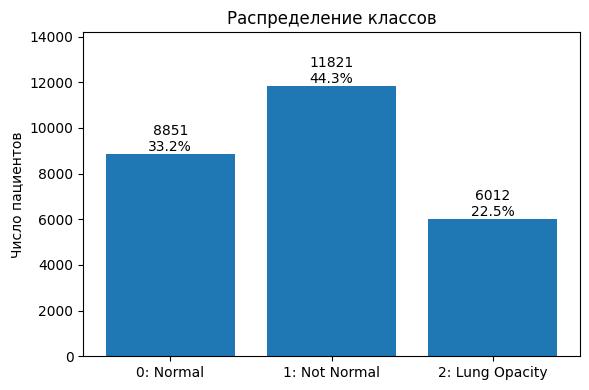

In [ ]:
import matplotlib.pyplot as plt

counts = labels["label"].value_counts().sort_index()
names = ["0: Normal", "1: Not Normal", "2: Lung Opacity"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(names, counts.values)
ax.bar_label(bars, labels=[f"{c}\n{c / counts.sum():.1%}" for c in counts.values])
ax.set_ylabel("Число пациентов")
ax.set_title("Распределение классов")
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.show()

### 2.2 Боксы
Сколько боксов на снимок, их размеры и где они лежат.

Боксов на снимок:
1    2614
2    3266
3     119
4      13
Name: count, dtype: int64

Размеры боксов:
        width  height
count  9555.0  9555.0
mean    218.5   329.3
std      59.3   157.8
min      40.0    45.0
25%     177.0   203.0
50%     217.0   298.0
75%     259.0   438.0
max     528.0   942.0


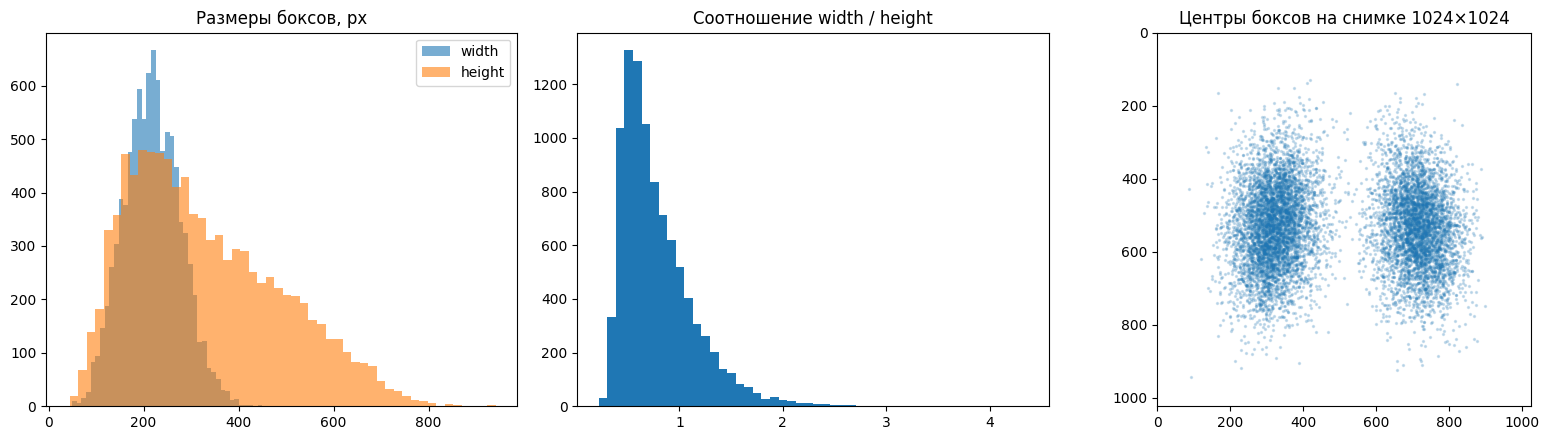

In [ ]:
import matplotlib.pyplot as plt

# сколько боксов на снимок
boxes_per_patient = boxes.groupby("patientId").size()
print("Боксов на снимок:")
print(boxes_per_patient.value_counts().sort_index())

# размеры боксов
print("\nРазмеры боксов:")
print(boxes[["width", "height"]].describe().round(1))

# центры боксов
cx = boxes["x"] + boxes["width"] / 2
cy = boxes["y"] + boxes["height"] / 2

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(boxes["width"], bins=50, alpha=0.6, label="width")
axes[0].hist(boxes["height"], bins=50, alpha=0.6, label="height")
axes[0].set_title("Размеры боксов, px")
axes[0].legend()

axes[1].hist(boxes["width"] / boxes["height"], bins=50)
axes[1].set_title("Соотношение width / height")

axes[2].scatter(cx, cy, s=2, alpha=0.2)
axes[2].set_xlim(0, 1024)
axes[2].set_ylim(0, 1024)
axes[2].invert_yaxis()
axes[2].set_aspect("equal")
axes[2].set_title("Центры боксов на снимке 1024×1024")

plt.tight_layout()
plt.show()

**Выводы.**
- пневмония чаще двусторонняя, снимков с двумя боксами больше, чем с одним, максимум 4 бокса;
- боксы крупные (медиана ≈ 217×298 px на 1024), самые маленькие - 40×45 px;
- центры боксов образуют два области - это и есть сами лёгкие; посередине (сердце, позвоночник) пусто.

### 2.3 Метаданные DICOM
Читаем только заголовки (`stop_before_pixels=True`)

In [ ]:
import pydicom
from pathlib import Path

train_image_path = extract_dir / "stage_2_train_images"
first_file_path = next(train_image_path.glob("*.dcm"),None)
ds = pydicom.dcmread(first_file_path, stop_before_pixels=True) #(stop_before_pixels=True отсекает тяжелые пиксельные данные)
print(ds)

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 202
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Secondary Capture Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.276.0.7230010.3.1.4.8323329.19417.1517874417.926741
(0002,0010) Transfer Syntax UID                 UI: JPEG Baseline (Process 1)
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.6.0
(0002,0013) Implementation Version Name         SH: 'OFFIS_DCMTK_360'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0016) SOP Class UID                       UI: Secondary Capture Image Storage
(0008,0018) SOP Instance UID                    UI: 1.2.276.0.7230010.3.1.4.8323329.19417.1517874417.926741
(0008,0020) Study Date                          DA: '19010101'
(0008,0030) Study Time                  

In [ ]:
import pydicom
from pathlib import Path

train_image_path = extract_dir / "stage_2_train_images"
metadata_list = []
target_tags = [
    "PatientID",
    "PhotometricInterpretation",
    "ViewPosition",
    "PatientSex",
    "PatientAge",
    "Rows",
    "Columns"
]

for file_path in train_image_path.glob("*.dcm"):
    try: # на случай ошибки dcmread
        ds = pydicom.dcmread(file_path, stop_before_pixels=True) # читаем только метаданные (без пикселей)
        file_data = {} # создаем словарь для текущего файла
        for tag in target_tags: # собираем нужные теги
            file_data[tag] = getattr(ds, tag, None) # getattr(ds, tag, None) вернет значение тега или None, если его нет
        metadata_list.append(file_data)

    except Exception as e:
        print(f"Ошибка при чтении файла {file_path.name}: {e}")

df = pd.DataFrame(metadata_list)
print(df.head(3))

                              PatientID PhotometricInterpretation  \
0  2458db44-f35a-4251-bebf-19514b25fd1c               MONOCHROME2   
1  6bc29d1f-fdf7-4c3a-ab66-c99f60d27bb8               MONOCHROME2   
2  ae7a7ed0-ea01-44de-9287-b2dec267bcfd               MONOCHROME2   

  ViewPosition PatientSex PatientAge  Rows  Columns  
0           PA          F         25  1024     1024  
1           AP          F         67  1024     1024  
2           AP          F         60  1024     1024  


In [ ]:
df = df.rename(columns={'PatientID': 'patientId'}, inplace=False)
df.head()

,patientId,PhotometricInterpretation,ViewPosition,PatientSex,PatientAge,Rows,Columns
0,2458db44-f35a-4251-bebf-19514b25fd1c,MONOCHROME2,PA,F,25,1024,1024
1,6bc29d1f-fdf7-4c3a-ab66-c99f60d27bb8,MONOCHROME2,AP,F,67,1024,1024
2,ae7a7ed0-ea01-44de-9287-b2dec267bcfd,MONOCHROME2,AP,F,60,1024,1024
3,0a34d5d9-8c50-4b97-9c9c-e5d6ed862a3d,MONOCHROME2,AP,M,19,1024,1024
4,ef27c260-e68c-4da3-bb4b-bf2e11fc34b2,MONOCHROME2,PA,M,56,1024,1024


In [ ]:
df["PatientAge"] = df["PatientAge"].astype(int)

In [ ]:
df['PatientAge'].describe()

,PatientAge
count,26684.000000
mean,47.030018
std,16.810578
min,1.000000
25%,34.000000
50%,49.000000
75%,59.000000
max,155.000000


In [ ]:
(df['PatientAge'] > 100).sum()

np.int64(5)

5 снимков с возрастом больше 100 лет это выбросы. Заменяем их медианой (на обучение возраст не влияет).

In [ ]:
median_age = df.loc[df['PatientAge'] <= 100, 'PatientAge'].median()

df.loc[df['PatientAge'] > 100, 'PatientAge'] = median_age

In [ ]:
df['PatientAge'].describe()

,PatientAge
count,26684.000000
mean,47.010830
std,16.749735
min,1.000000
25%,34.000000
50%,49.000000
75%,59.000000
max,92.000000


In [ ]:
df['PatientSex'].describe()

,PatientSex
count,26684
unique,2
top,M
freq,15166


In [ ]:
df['PhotometricInterpretation'].describe()

,PhotometricInterpretation
count,26684
unique,1
top,MONOCHROME2
freq,26684


In [ ]:
df['Rows'].describe()

,Rows
count,26684.0
mean,1024.0
std,0.0
min,1024.0
25%,1024.0
50%,1024.0
75%,1024.0
max,1024.0


In [ ]:
df['Columns'].value_counts()

,count
Columns,
1024,26684


In [ ]:
df['ViewPosition'].describe()

,ViewPosition
count,26684
unique,2
top,PA
freq,14511


In [ ]:
df.to_csv("dicom_metadata_table.csv", index=False)
print("таблица сохранена в dicom_metadata_table.csv")

таблица сохранена в dicom_metadata_table.csv


In [ ]:
meta = pd.merge(labels, df, on="patientId", how="inner")
assert len(meta) == 26684

In [ ]:
meta.drop(columns=["PhotometricInterpretation"], inplace=True)
meta.drop(columns=["Columns"], inplace=True)
meta.drop(columns=["Rows"], inplace=True)


### 2.4 Проекция AP/PA и класс

AP-снимки делают лежачим и тяжёлым пациентам, поэтому среди них пневмония встречается в разы чаще.
Модель может выучить, что AP == болен вместо самих признаков в лёгких.

In [ ]:
pd.crosstab(meta["label"], meta["ViewPosition"], normalize="index")

ViewPosition,AP,PA
label,,
0,0.184951,0.815049
1,0.496743,0.503257
2,0.775782,0.224218


In [ ]:
from sklearn.metrics import roc_auc_score
auc = roc_auc_score(meta["label"] == 2, meta["ViewPosition"]=='AP')
print(auc)

0.7062684003767491


Только по проекции, не видя лёгких, AUC класса 2 уже **0.706**. Это нижняя планка, модель должна заметно её превзойти, причём внутри каждой проекции отдельно.

### 2.5 Снимки глазами
По 12 снимков каждого класса с боксами.

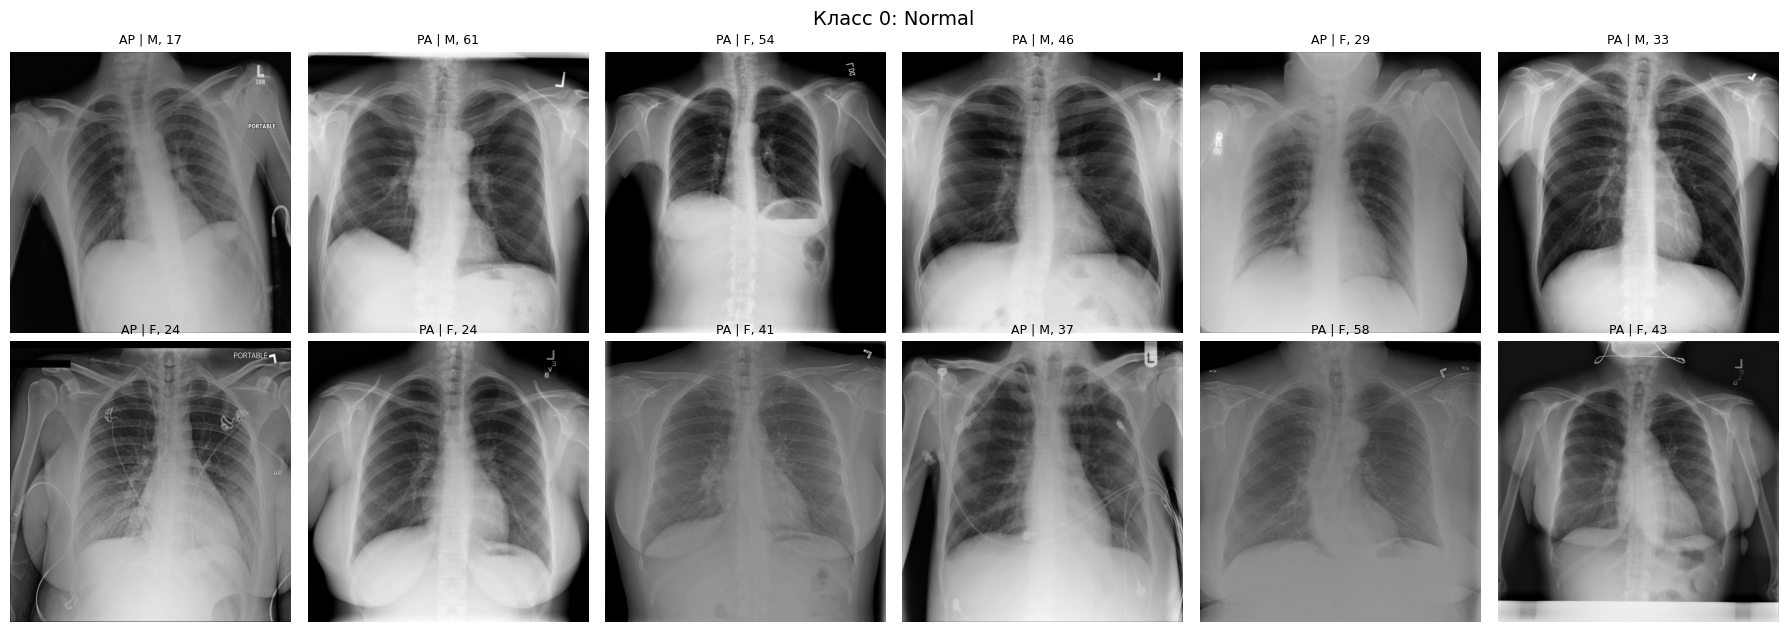

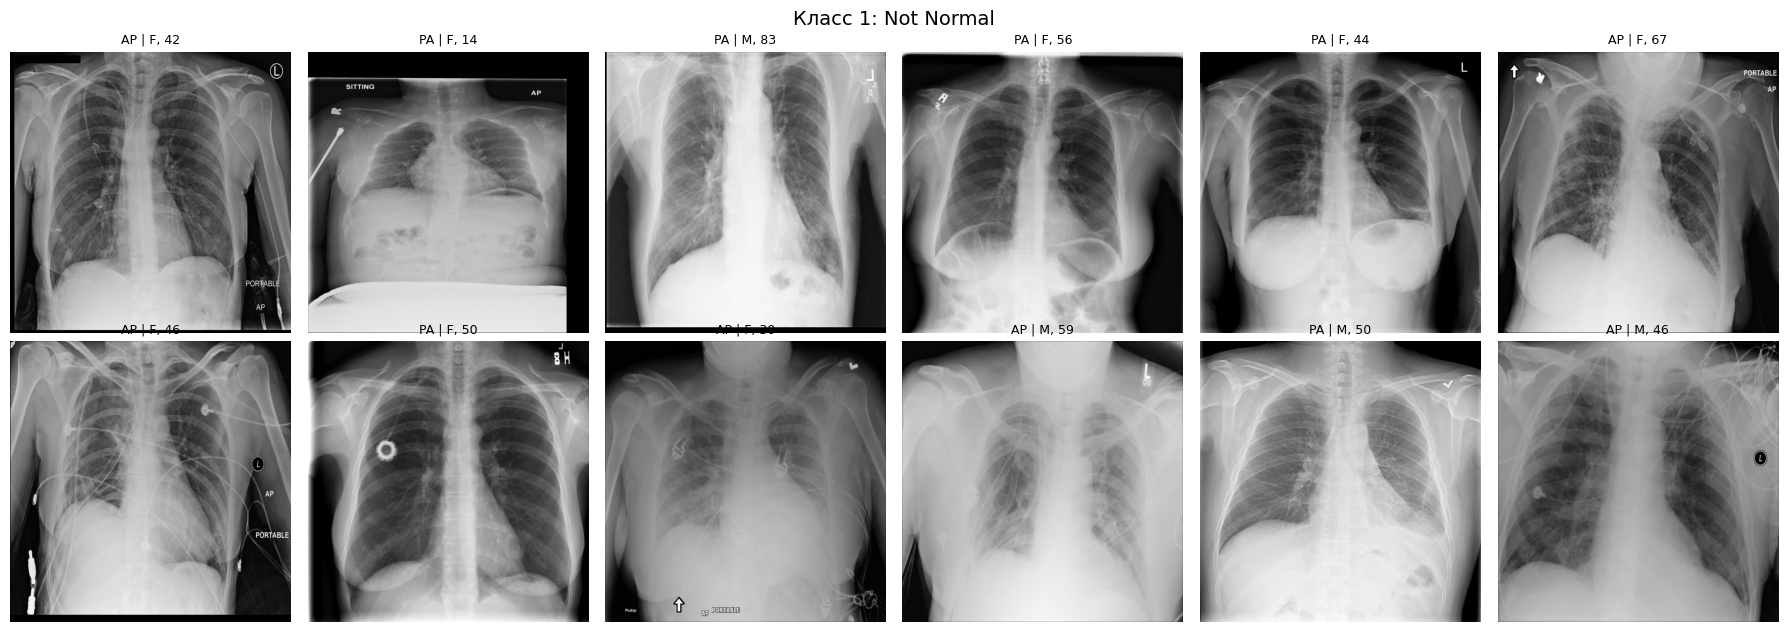

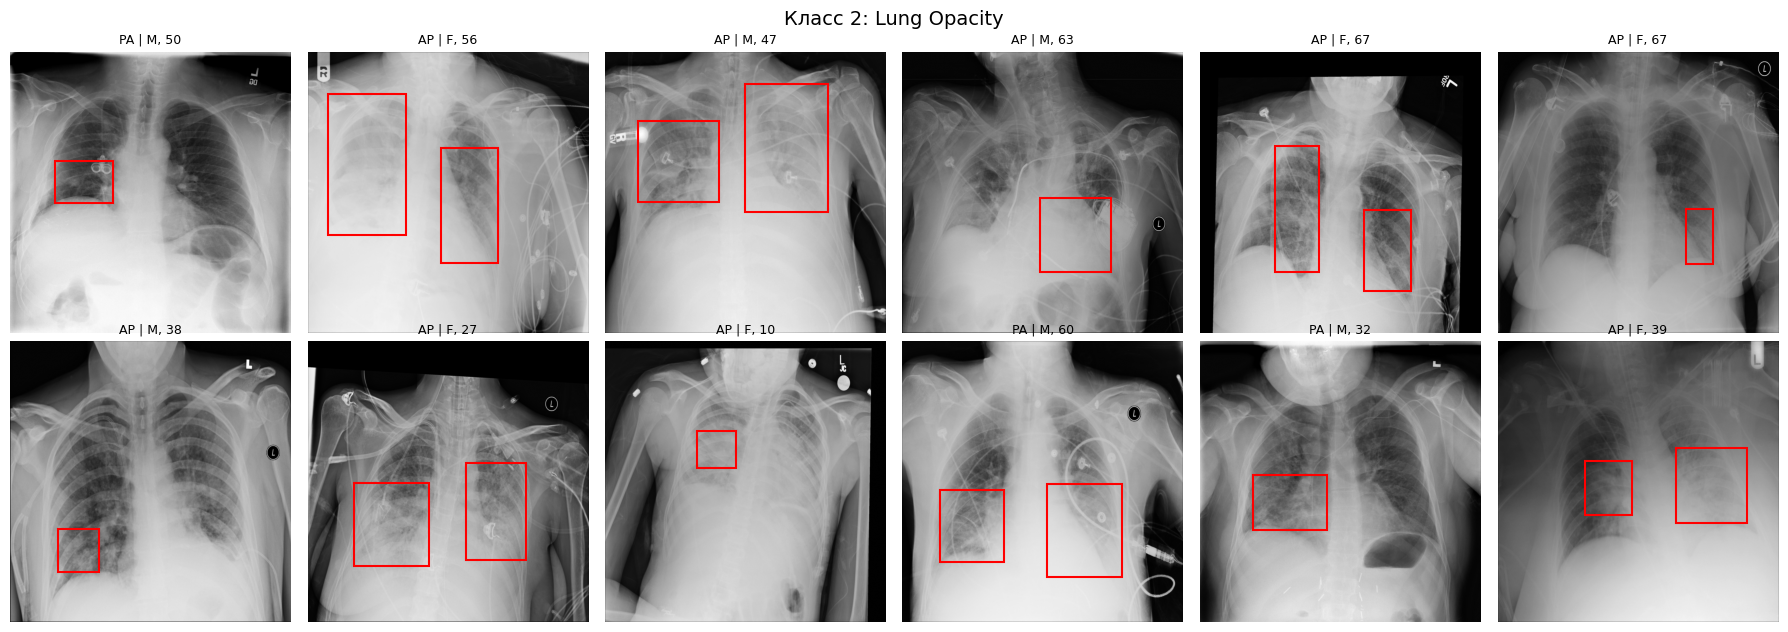

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pydicom

train_dir = extract_dir / "stage_2_train_images"
class_names = {0: "Normal", 1: "Not Normal", 2: "Lung Opacity"}

def show_class(label, n=12, seed=0, cols=6):
    sample = meta[meta["label"] == label].sample(n, random_state=seed)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3.2 * rows))

    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        img = pydicom.dcmread(train_dir / f"{row.patientId}.dcm").pixel_array
        ax.imshow(img, cmap="gray")

        for _, b in boxes[boxes["patientId"] == row.patientId].iterrows():
            ax.add_patch(patches.Rectangle(
                (b.x, b.y), b.width, b.height,
                fill=False, edgecolor="red", linewidth=1.5,
            ))

        ax.set_title(f"{row.ViewPosition} | {row.PatientSex}, {row.PatientAge}", fontsize=9)
        ax.axis("off")

    for ax in axes.flat[n:]:
        ax.axis("off")

    fig.suptitle(f"Класс {label}: {class_names[label]}", fontsize=14)
    plt.tight_layout()
    plt.show()

for label in [0, 1, 2]:
    show_class(label)

По снимкам видно, что маркеры L/R и надписи `PORTABLE` стоят в основном по краям, чёрные рамки встречаются редко.

## 3. Препроцессинг

`DICOM -> float32 -> (инверсия, если MONOCHROME1) -> перцентильный клип 0.5–99.5% -> 0..255 uint8 -> ресайз 512`.

Ресайз до 512 уменьшает и координаты боксов, их достаточно умножить на `scale = 512 / 1024`.

> Не реализовано.
 
> В исходном плане между клипом и ресайзом стоял кроп по лёгким.
> (сегментация лёгких готовой моделью -> bbox лёгких с отступом -> кроп -> пересчёт боксов со сдвигом).
> В итоговой версии проекта этого шага нет. Первые тестовые модели на efficiencynet подсматривали на надписи на изображении (L/R и `PORTABLE`), поэтому давали более низкие результаты в конечном тесте, после пересмотра выбора модели проблема исчезла, поэтому модель работает по всему снимку.

In [ ]:
import pydicom
import cv2
import numpy as np
import sys
def percentile_clip(data, lower_percentile=0.5, upper_percentile=99.5):
    # 1. Вычисляем значения порогов для заданных перцентилей
    low_val, high_val = np.percentile(data, [lower_percentile,upper_percentile])

    # 2. Обрезаем (клипаем) массив по этим значениям
    clipped_data = np.clip(data, low_val, high_val)

    return clipped_data
def read_dicom(dicom_path):
    dcm = pydicom.dcmread(dicom_path)

    img = dcm.pixel_array.astype('float32')  # Извлекаем матрицу пикселей
    if dcm.PhotometricInterpretation == "MONOCHROME1": #проверка на монохром, просто часть функции на будущее
        img = img.max() - img
    img = percentile_clip(img)
    img = (img - np.min(img)) / (np.max(img) - np.min(img) + sys.float_info.epsilon) # Нормализация в [0, 1] +защита от деления на ноль, в числителе все равно - будет просто черная картинка
    img = np.round(img * 255).astype(np.uint8) #растягиваем до 255 и потом uint8

    return img

def resize_img(img,size=512):
    resized_img = cv2.resize(img, (size,size), interpolation=cv2.INTER_AREA) #ресайз
    scale =  resized_img.shape[0]/img.shape[0]
    return resized_img, scale

def resize_boxes(df, scale):
    df1 = df.copy()
    cols = ['x', 'y', 'width', 'height']
    df1[cols] = df1[cols] * scale
    return df1

Проверка. Боксы после ресайза ложатся на те же места, `scale = 0.5`.

scale: 0.5


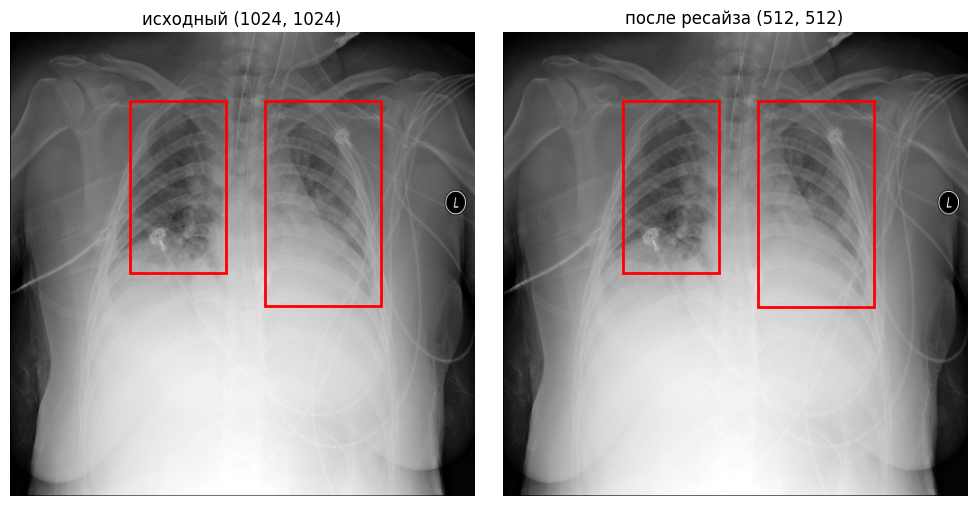

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

pid = boxes["patientId"].iloc[0]   # первый пациент с боксами
img = read_dicom(train_dir / f"{pid}.dcm")
img_small, scale = resize_img(img, 512)
boxes_512 = resize_boxes(boxes, scale)

print("scale:", scale)   # должно быть 0.5

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, im, bx, title in [
    (axes[0], img, boxes, f"исходный {img.shape}"),
    (axes[1], img_small, boxes_512, f"после ресайза {img_small.shape}"),
]:
    ax.imshow(im, cmap="gray")
    for _, b in bx[bx["patientId"] == pid].iterrows():
        ax.add_patch(patches.Rectangle((b.x, b.y), b.width, b.height,
                                       fill=False, edgecolor="red", linewidth=2))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Все снимки в память
26 684 × 512 × 512 × 1 байт ≈ 6.5 ГБ. Снимки читаются параллельно на всех ядрах (joblib) и складываются в заранее созданный массив, что позволяет не дублировать память.

In [ ]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:            83Gi       2.9Gi        58Gi       3.0Mi        23Gi        80Gi
Swap:             0B          0B          0B


In [ ]:
import numpy as np
from joblib import Parallel, delayed
from tqdm import tqdm
DEBUG = False
# Исходные данные
resize = 512
if DEBUG and len(meta) == 26684:
    meta = meta.sample(frac=0.2, random_state=42).reset_index(drop=True)
num_images = len(meta)
def process_single_patient(i, patient_id):

    image_after_read = read_dicom(train_image_path / (patient_id + ".dcm"))
    image_after_resize, scale_of_resize = resize_img(image_after_read, size=resize)

    return i, image_after_resize, scale_of_resize

images = np.zeros((num_images, resize, resize), dtype=np.uint8)

scales = [None] * num_images

with Parallel(n_jobs=-1, return_as="generator") as parallel:
    # Генератор задач для joblib
    tasks = (delayed(process_single_patient)(i, meta['patientId'][i]) for i in range(num_images))

    for i, img, scale in tqdm(parallel(tasks), total=num_images, desc="Processing DICOMs"):
        images[i] = img
        scales[i] = scale

last_scale = scales[-1]
resized_boxes = resize_boxes(boxes, scale=last_scale)


print(f"Размер массива в памяти: {images.nbytes / (1024**2):.2f} MB")

Processing DICOMs: 100%|██████████| 26684/26684 [02:04<00:00, 213.56it/s]

Размер массива в памяти: 6671.00 MB


## 4. Сплит train / val / test

60 / 20 / 20 со стратификацией по `класс + проекция`. Колонка `split` сохраняется в `meta_classifier_ConvNeXt_V2_Tiny_no_aug.csv` - ноутбук YOLO берёт деление оттуда, поэтому у обеих моделей оно одинаковое.

In [ ]:
from sklearn.model_selection import train_test_split
meta["strat_key"] = meta["label"].astype(str) + "_" + meta["ViewPosition"]
# отделяем test: 20% строк meta
train_val, test = train_test_split(meta, test_size=0.20, random_state=SEED,
                                   stratify=meta["strat_key"])

# из оставшихся 80% отделяем val: 0.25 * 0.8 = 20% от всех
train, val = train_test_split(train_val, test_size=0.25, random_state=SEED,
                              stratify=train_val["strat_key"])

# одписываем строки meta
meta["split"] = "train"
meta.loc[val.index, "split"] = "val"
meta.loc[test.index, "split"] = "test"

# проверка
print(meta["split"].value_counts())
print(pd.crosstab(meta["split"], meta["strat_key"], normalize="index").round(3))

# сохранить один раз для всех ноутбуков
meta.to_csv(drive_dir / "meta_classifier_ConvNeXt_V2_Tiny_no_aug.csv", index=False)
resized_boxes.to_csv(drive_dir / "boxes_512_classifier_ConvNeXt_V2_Tiny_no_aug.csv", index=False)

split
train    16010
val       5337
test      5337
Name: count, dtype: int64
strat_key   0_AP  0_PA  1_AP   1_PA   2_AP   2_PA
split                                            
test       0.061  0.27  0.22  0.223  0.175  0.051
train      0.061  0.27  0.22  0.223  0.175  0.051
val        0.061  0.27  0.22  0.223  0.175  0.050


## 5. Dataset и DataLoader

`Dataset` хранит ссылку на общий массив снимков и номера своих строк, ничего не копирует. Возвращает тензор `(1, 512, 512)` в диапазоне 0..1 и метку класса.

In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch

class CXRDataset(Dataset):
    def __init__(self, images, labels, indices, transform=None):
        self.images = images          # ссылка на весь массив (N, 512, 512), без копии
        self.labels = labels          # метки всех N строк, numpy-массив
        self.indices = indices        # номера строк этого датасета
        self.transform = transform

    def __len__(self):
        return len(self.indices)      # сколько снимков в ЭТОМ датасете

    def __getitem__(self, i):
        idx = self.indices[i]         # номер внутри датасета -> номер в общем массиве

        img = self.images[idx]        # только читаем, в общий массив не пишем
        label = self.labels[idx]

        if self.transform is not None:
            img = self.transform(image=img)["image"] # аугментация над локальной копией

        img = torch.from_numpy(img).float().div(255).unsqueeze(0)  # (1, 512, 512), 0..1
        label = torch.tensor(label, dtype=torch.long)
        return img, label

In [ ]:
labels = meta["label"].values
train_indices = np.where(meta["split"] == "train")[0]
val_indices = np.where(meta["split"] == "val")[0]
test_indices = np.where(meta["split"] == "test")[0]

train_ds = CXRDataset(images, labels, train_indices)
val_ds = CXRDataset(images, labels, val_indices)
test_ds = CXRDataset(images, labels, test_indices, transform=None)

print(len(train_ds), len(val_ds))
x, y = val_ds[0]
print(x.shape, x.dtype, x.min().item(), x.max().item(), y)

16010 5337
torch.Size([1, 512, 512]) torch.float32 0.0 1.0 tensor(1)


In [ ]:
import os
cores = os.cpu_count()

На лоадер берем все доступные ядра, но лучше брать core-1, чтобы не мешать организации других процессов. В данном проекте это не учитывалось

In [ ]:
train_loader = DataLoader(
    train_ds,
    batch_size=64,  # размер батча
    shuffle=True,  # перемешивать данные каждую эпоху
    num_workers=cores,
    pin_memory=True,
    persistent_workers=True,
)
val_loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)
test_loader = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

Замер скорости загрузчика без модели (50 батчей).

In [ ]:
import time
start = time.perf_counter()
for step, (x, y) in enumerate(train_loader):
    if step == 50: break
all_time = time.perf_counter() - start

In [ ]:
print(all_time)

3.6561344810002083


## 6. Аугментации

Флип, поворот ±10°, масштаб ±10%, сдвиг ±5%, перспектива, яркость/контраст/гамма, шум, CoarseDropout.

> В финальном запуске `train_ds` был создан без `transform=get_transforms()`, поэтому модель обучалась без аугментаций. Это видно по быстрому переобучению (train loss падает до 0.10, val loss растёт после 4-й эпохи).

In [ ]:
import albumentations as A

def get_transforms():
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05),
                 rotate=(-10, 10), p=0.7),
        A.Perspective(scale=(0.02, 0.05), p=0.3),
        A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
        A.RandomGamma(gamma_limit=(80, 120), p=0.3),
        A.GaussNoise(std_range=(0.01, 0.04), p=0.2),
        A.CoarseDropout(num_holes_range=(1, 4),
                        hole_height_range=(0.04, 0.10),
                        hole_width_range=(0.04, 0.10),
                        fill=0, p=0.3),
    ])

## 7. Модель

ConvNeXt V2 Tiny из `timm`, предобучена на ImageNet. Вход - 1 канал (timm сам складывает веса RGB), выход - 3 класса.

In [ ]:
import timm
model = timm.create_model(
    "convnextv2_tiny.fcmae_ft_in22k_in1k", #на imagenet
    pretrained=True,
    num_classes=3, #выходной слой классов
    in_chans=1, #входной - 3 rgb - 1 отенки серого, можно и 3 но придется дублировать
    drop_rate = 0.2,
    drop_path_rate = 0.1)

model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

Пример выхода на одном батче. Логиты `(B, 3)` -> softmax -> вероятности.

In [ ]:
MEAN, STD = 0.449, 0.226   # ImageNet, усреднено по трём каналам

def prepare_batch(x): #усреднение по ImageNet
    return (x - MEAN) / STD

x, y = next(iter(train_loader))   # один батч

model.eval()
with torch.no_grad():
    logits = model(prepare_batch(x))       # (B, 3)
    probs = torch.softmax(logits, dim=1)   # (B, 3), каждая строка в сумме = 1 - тензор вероятностей
    preds = probs.argmax(dim=1)            # (B,)

print(logits.shape)
print(probs.sum(dim=1))
print("preds:", preds)
print("y:    ", y)

torch.Size([64, 3])
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000])
preds: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])
y:     tensor([0, 0, 1, 2, 2, 0, 1, 1, 1, 2, 0, 2, 0, 2, 2, 1, 0, 1, 1, 1, 1, 1, 0, 2,
        0, 1, 2, 1, 1, 2, 0, 2, 1, 2, 0, 0, 1, 1, 1, 1, 1, 1, 2, 0, 1, 0, 0, 0,
        1, 1

## 8. Обучение

- `CrossEntropyLoss` с весами классов (считаются только по train)
- `AdamW`, lr 1e-4, `OneCycleLR` (разогрев 10% шагов, затем косинус)
- bf16 autocast на GPU, ограничение градиента `clip_grad_norm_ = 1.0`
- сохраняются две модели, лучшая по macro F1 (`classifier_best_for_f1_classifier_ConvNeXt_V2_Tiny_no_aug.pt` + `val_probs_classifier_ConvNeXt_V2_Tiny_no_aug.csv`) и лучшая по val loss
- ранняя остановка по val loss, `patience = 5`

In [ ]:
class EarlyStopping:
    """Ранняя остановка обучения, если валидационный лосс не улучшается."""
    def __init__(self, patience=7, verbose=False, delta=0):
        """
        Args:
            patience (int): Сколько эпох ждать после последнего улучшения.
            verbose (bool): Если True, выводит сообщение о каждом улучшении.
            delta (float): Минимальное изменение, считающееся как улучшение.
            path (str): Путь для сохранения лучшей модели.
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf
        self.delta = delta

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        """Сохраняет модель при уменьшении валидационного лосса."""
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model ...')
        torch.save(model.state_dict(), out_dir / "classifier_best_for_val_classifier_ConvNeXt_V2_Tiny_no_aug.pt")
        self.val_loss_min = val_loss

In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
from pathlib import Path
from sklearn.metrics import roc_auc_score, f1_score, recall_score
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

# настройки
MODEL_NAME = "convnextv2_tiny.fcmae_ft_in22k_in1k"
EPOCHS = 30
LR = 1e-4
WEIGHT_DECAY = 0.05
MEAN, STD = 0.449, 0.226 # нормализация ImageNet для одного канала
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
out_dir = Path("/content/drive/MyDrive/rsna_project_final/classifier_ConvNeXt_V2_Tiny_no_aug")
out_dir.mkdir(parents=True, exist_ok=True)

# модель, ошибка, оптимизатор
model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=3, in_chans=1,
                          drop_rate=0.2, drop_path_rate=0.1).to(DEVICE)

train_labels = labels[train_indices]
weights = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=train_labels)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE))

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR( # dynamic lr
    optimizer, max_lr=LR, total_steps=EPOCHS * len(train_loader), pct_start=0.1)

use_amp = DEVICE == "cuda"   # bf16 на GPU, обычный fp32 на CPU

# обучение
best_f1, history = -1.0, []

early_stopping = EarlyStopping(patience=5, verbose=True)

for epoch in range(EPOCHS):
    start = time.time()

    # --- эпоха обучения ---
    model.train()
    train_loss, n = 0.0, 0
    for x, y in tqdm(train_loader, leave=False, desc=f"train {epoch}"):
        x = ((x - MEAN) / STD).to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=use_amp):
            logits = model(x)
        loss = criterion(logits.float(), y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        train_loss += loss.item() * len(x)
        n += len(x)
    train_loss /= n

    # --- валидация ---
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for x, y in tqdm(val_loader, leave=False, desc=f"val {epoch}"):
            x = ((x - MEAN) / STD).to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=use_amp):
                logits = model(x)
            probs.append(torch.softmax(logits.float(), dim=1).cpu())
            ys.append(y)
    probs = torch.cat(probs).numpy()           # (N_val, 3)
    ys = torch.cat(ys).numpy()                 # (N_val,)
    preds = probs.argmax(1)

    val_loss = nn.functional.nll_loss(torch.log(torch.tensor(probs).clamp_min(1e-8)),
                                      torch.tensor(ys)).item()
    auc = roc_auc_score(ys, probs, multi_class="ovr")
    f1 = f1_score(ys, preds, average="macro")
    rec2 = recall_score(ys, preds, labels=[2], average="macro")
    # --- запись в историю ---
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                        auc=auc, f1=f1, rec2=rec2))
    print(f"ep {epoch} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} | auc {auc:.4f} | "
          f"f1 {f1:.4f} | rec2 {rec2:.4f} | {time.time() - start:.0f}s")

    # --- лучшая эпоха: веса и вероятности на val ---
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), out_dir / "classifier_best_for_f1_classifier_ConvNeXt_V2_Tiny_no_aug.pt")
        val_df = meta.iloc[val_indices][["patientId", "label", "ViewPosition"]].copy()
        val_df[["prob0", "prob1", "prob2"]] = probs
        val_df.to_csv(out_dir / "val_probs_classifier_ConvNeXt_V2_Tiny_no_aug.csv", index=False)

    # --- проверка Early Stopping ---
    early_stopping(val_loss, model)

    if early_stopping.early_stop:
        print("Ранняя остановка сработала. Обучение прекращено.")
        break

pd.DataFrame(history).to_csv(out_dir / "history_clssifier_classifier_ConvNeXt_V2_Tiny_no_aug.csv", index=False)
print(f"лучший macro F1: {best_f1:.4f}")

train 0:   0%|          | 0/251 [00:00<?, ?it/s]

val 0:   0%|          | 0/167 [00:00<?, ?it/s]

ep 0 | train_loss 0.8742 | val_loss 0.6964 | auc 0.8588 | f1 0.6698 | rec2 0.7013 | 178s
Validation loss decreased (inf --> 0.696407). Saving model ...


train 1:   0%|          | 0/251 [00:00<?, ?it/s]

val 1:   0%|          | 0/167 [00:00<?, ?it/s]

...

val 8:   0%|          | 0/167 [00:00<?, ?it/s]

ep 8 | train_loss 0.1290 | val_loss 1.2228 | auc 0.8804 | f1 0.7171 | rec2 0.5757 | 166s
EarlyStopping counter: 4 out of 5


train 9:   0%|          | 0/251 [00:00<?, ?it/s]

val 9:   0%|          | 0/167 [00:00<?, ?it/s]

ep 9 | train_loss 0.1018 | val_loss 1.2034 | auc 0.8750 | f1 0.7114 | rec2 0.5915 | 166s
EarlyStopping counter: 5 out of 5
Ранняя остановка сработала. Обучение прекращено.
лучший macro F1: 0.7349


## 9. Проверка на test

Метрики, отчёт по классам, матрица ошибок и проверка shortcut. AUC класса 2 по всем снимкам, только по проекции и внутри AP и PA.

In [ ]:
from sklearn.metrics import roc_auc_score, f1_score, recall_score, confusion_matrix, classification_report

def get_probs(model_pt: str, save_dir: str):
    save_dir = Path(save_dir)
    model_pt = Path(model_pt)
    model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=3, in_chans=1)
    model.load_state_dict(torch.load(out_dir / model_pt, map_location=DEVICE))
    model = model.to(DEVICE).eval()

    # ---предсказания---
    probs, ys = [], []
    with torch.no_grad():
        for x, y in tqdm(test_loader, desc="test"):
            x = ((x - MEAN) / STD).to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEVICE == "cuda"):
                logits = model(x)
            probs.append(torch.softmax(logits.float(), dim=1).cpu())
            ys.append(y)
    probs = torch.cat(probs).numpy()
    ys = torch.cat(ys).numpy()
    preds = probs.argmax(1)

    # ---метрики---
    print(f"test: {len(ys)} снимков")
    print(f"ROC-AUC (ovr): {roc_auc_score(ys, probs, multi_class='ovr'):.4f}")
    print(f"macro F1:      {f1_score(ys, preds, average='macro'):.4f}")
    print(f"recall класса 2: {recall_score(ys, preds, labels=[2], average='macro'):.4f}")
    print("\n", classification_report(ys, preds, target_names=["0 Normal", "1 Not Normal", "2 Opacity"], digits=3))
    print(pd.DataFrame(confusion_matrix(ys, preds),
                      index=["правда 0", "правда 1", "правда 2"],
                      columns=["предсказано 0", "предсказано 1", "предсказано 2"]))

    # ---shortcut: класс 2 против проекции---
    test_df = meta.iloc[test_indices][["patientId", "label", "ViewPosition"]].copy()
    test_df[["prob0", "prob1", "prob2"]] = probs
    y2 = test_df["label"] == 2

    print(f"\nAUC класса 2, все снимки:  {roc_auc_score(y2, test_df['prob2']):.4f}")
    print(f"только по проекции AP/PA:  {roc_auc_score(y2, test_df['ViewPosition'] == 'AP'):.4f}")
    for vp in ["AP", "PA"]:
        m = test_df["ViewPosition"] == vp
        print(f"внутри {vp}: {roc_auc_score(y2[m], test_df.loc[m, 'prob2']):.4f}")

    test_df.to_csv(out_dir / save_dir, index=False)



In [ ]:
get_probs(model_pt = "classifier_best_for_f1_classifier_ConvNeXt_V2_Tiny_no_aug.pt", save_dir = "test_probs_f1_classifier_ConvNeXt_V2_Tiny_no_aug.csv")

test:   0%|          | 0/167 [00:00<?, ?it/s]

test: 5337 снимков
ROC-AUC (ovr): 0.8895
macro F1:      0.7259
recall класса 2: 0.6675

               precision    recall  f1-score   support

    0 Normal      0.769     0.917     0.836      1770
1 Not Normal      0.748     0.629     0.683      2364
   2 Opacity      0.649     0.667     0.658      1203

    accuracy                          0.733      5337
   macro avg      0.722     0.738     0.726      5337
weighted avg      0.732     0.733     0.728      5337

          предсказано 0  предсказано 1  предсказано 2
правда 0           1623            142              5
правда 1            448           1487            429
правда 2             40            360            803

AUC класса 2, все снимки:  0.8895
только по проекции AP/PA:  0.7062
внутри AP: 0.8434
внутри PA: 0.8748


Для сравнения, модель, выбранная по val loss (в цепочке не используется, пороги подбирались по вероятностям модели, выбранной по F1).

In [ ]:
get_probs(model_pt = "classifier_best_for_val_classifier_ConvNeXt_V2_Tiny_no_aug.pt", save_dir = "test_probs_val_classifier_ConvNeXt_V2_Tiny_no_aug.csv")

test:   0%|          | 0/167 [00:00<?, ?it/s]

test: 5337 снимков
ROC-AUC (ovr): 0.8940
macro F1:      0.7311
recall класса 2: 0.7149

               precision    recall  f1-score   support

    0 Normal      0.817     0.871     0.843      1770
1 Not Normal      0.744     0.644     0.690      2364
   2 Opacity      0.613     0.715     0.660      1203

    accuracy                          0.735      5337
   macro avg      0.725     0.743     0.731      5337
weighted avg      0.739     0.735     0.734      5337

          предсказано 0  предсказано 1  предсказано 2
правда 0           1542            212             16
правда 1            315           1522            527
правда 2             30            313            860

AUC класса 2, все снимки:  0.8927
только по проекции AP/PA:  0.7062
внутри AP: 0.8403
внутри PA: 0.8842


**Выводы по test.**
- норма распознаётся хорошо; основная путаница между классами 1 и 2;
- AUC класса 2 равен 0.890 против 0.706 «только по проекции», внутри AP 0.843, внутри PA 0.875 -> модель различает пневмонию внутри одной проекции, то есть смотрит на лёгкие, а не только на способ съёмки.

## 10. Grad-CAM

Куда смотрит модель, когда видит пневмонию. Код почти без изменений взят из [jacobgil/pytorch-grad-cam](https://github.com/jacobgil/pytorch-grad-cam) (MIT).

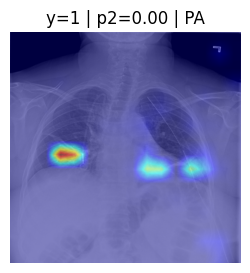

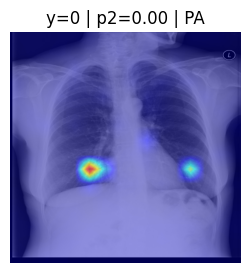

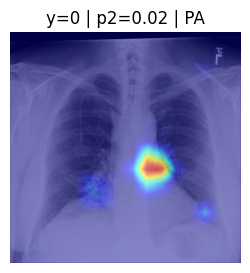

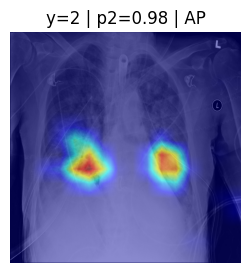

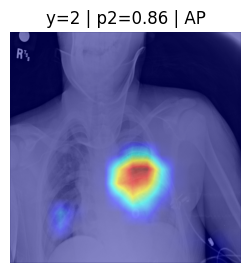

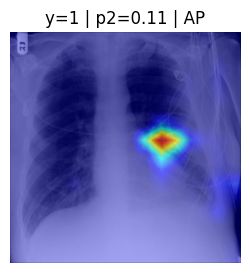

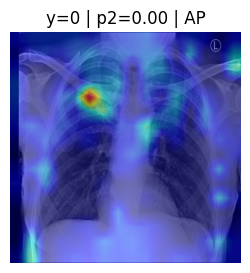

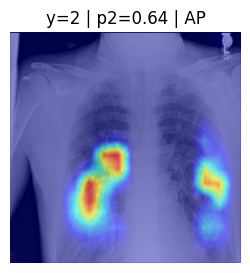

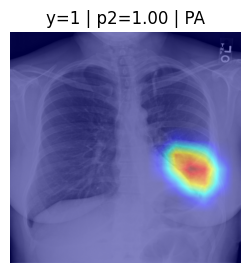

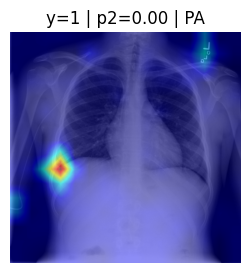

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
import numpy as np
import torch

target_layers = [model.stages[-1]]
for y in range(10):
    i = val_indices[y] # номер снимка в images
    img = images[i] # (512, 512) uint8
    input_tensor = prepare_batch(torch.from_numpy(img).float().div(255)[None, None]).to(DEVICE)
    rgb_img = np.repeat(img[..., None], 3, axis=2).astype(np.float32) / 255   # серый -> (H, W, 3), 0..1

    # We have to specify the target we want to generate the CAM for.
    targets = [ClassifierOutputTarget(2)]
    # Construct the CAM object once, and then re-use it on many images.
    with GradCAM(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
        # In this example grayscale_cam has only one image in the batch:
        grayscale_cam = grayscale_cam[0, :]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
        # You can also get the model outputs without having to redo inference
        model_outputs = cam.outputs

    p2 = torch.softmax(model_outputs, dim=1)[0, 2].item()
    plt.figure(figsize=(3, 3))
    plt.imshow(visualization)
    plt.title(f"y={meta.iloc[i].label} | p2={p2:.2f} | {meta.iloc[i].ViewPosition}")
    plt.axis("off")
    plt.show()

## 11. Порог по коэффициенту Жаккара

`J = TP / (TP + FP + FN)` для решения пневмония / нет. Порог по `prob2` подбирается на val и проверяется на test.

лучший порог prob2: 0.49 | Жаккар на val: 0.5169
Жаккар на test: 0.4936 (с порогом) | 0.4905 (по argmax)


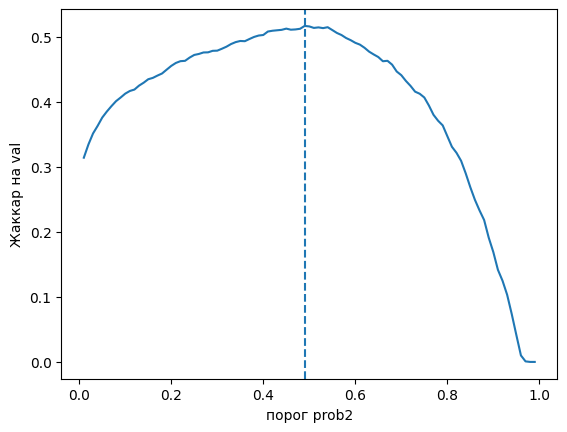

In [ ]:
from sklearn.metrics import jaccard_score

def best_jaccard_threshold(y_true, p, thresholds=np.linspace(0.01, 0.99, 99)):
    """Порог по вероятности, при котором Жаккар максимален. Все пороги считаются разом."""
    y = np.asarray(y_true, dtype=bool)
    pred = np.asarray(p)[None, :] >= thresholds[:, None]      # (число порогов, число снимков)
    tp = (pred & y).sum(1)
    fp = (pred & ~y).sum(1)
    fn = (~pred & y).sum(1)
    jac = tp / np.maximum(tp + fp + fn, 1)
    i = jac.argmax()
    return thresholds[i], jac[i], thresholds, jac


# подбор на val
val = pd.read_csv(out_dir / "val_probs_classifier_ConvNeXt_V2_Tiny_no_aug.csv")
thr, j_val, ts, js = best_jaccard_threshold(val["label"] == 2, val["prob2"])
print(f"лучший порог prob2: {thr:.2f} | Жаккар на val: {j_val:.4f}")

# проверка на test, порог тот же
test = pd.read_csv(out_dir / "test_probs_f1_classifier_ConvNeXt_V2_Tiny_no_aug.csv")
j_test = jaccard_score(test["label"] == 2, test["prob2"] >= thr)
j_argmax = jaccard_score(test["label"] == 2, test[["prob0", "prob1", "prob2"]].to_numpy().argmax(1) == 2)
print(f"Жаккар на test: {j_test:.4f} (с порогом) | {j_argmax:.4f} (по argmax)")

plt.plot(ts, js)
plt.axvline(thr, ls="--")
plt.xlabel("порог prob2"); plt.ylabel("Жаккар на val")
plt.show()